## Question 1

In [1]:
import pandas as pd
import json
import warnings

warnings.filterwarnings('ignore')

with open('research_abstracts.json', 'r', encoding='utf-8') as file:
    data = json.load(file)

# JSON data into a DataFrame
df = pd.DataFrame(data)

df.head()

,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names and data types
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Distribution of research categories
print("\nLabel distribution:")
print(df['Label'].value_counts())

Dataset shape: (1138, 3)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 35.6+ KB

Missing values:
DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate records: 2

Label distribution:
Label
classical    900
ai           238
Name: count, dtype: int64


In [3]:
# Removing duplicate records
df = df.drop_duplicates()

# Resetting the DataFrame index
df = df.reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate records:", df.duplicated().sum())

Dataset shape after removing duplicates: (1136, 3)
Remaining duplicate records: 0


In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Text denoising techniques
# NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


stop_words = set(stopwords.words('english'))


stop_words = stop_words - {'no', 'not', 'nor'}

# Text preprocessing function
def preprocess(text):

    
    clean_text = text.lower()

    
    clean_text = re.sub(r'[^a-zA-Z\s]', ' ', clean_text)

   
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    
    words = word_tokenize(clean_text)

    
    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    
    clean_text = ' '.join(filtered_words)

    return clean_text


# Preprocessing to the Abstract column
df['Clean_Abstract'] = df['Abstract'].apply(preprocess)

# Original and cleaned abstracts
df[['Abstract', 'Clean_Abstract', 'Label']].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Tbose\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Tbose\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Tbose\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Abstract,Clean_Abstract,Label
0,Forward-looking forecasting of the inflation r...,forward looking forecasting inflation rate cou...,ai
1,Our study examined the disaggregation of infla...,study examined disaggregation inflation compon...,ai
2,This paper develops a dynamic factor model tha...,paper develops dynamic factor model uses euro ...,classical
3,"In this paper, I use a simple SIR Macro model ...",paper use simple sir macro model examine japan...,classical
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory useful identifying condi...,classical


In [5]:
print("Original abstract:")
print(df['Abstract'].iloc[0])

print("\nCleaned abstract:")
print(df['Clean_Abstract'].iloc[0])

# The length of the original and cleaned abstracts
df['Original_Length'] = df['Abstract'].str.len()
df['Cleaned_Length'] = df['Clean_Abstract'].str.len()

print("\nAverage original abstract length:",
      df['Original_Length'].mean())

print("Average cleaned abstract length:",
      df['Cleaned_Length'].mean())


print("\nFinal dataset shape:", df.shape)
df.head()

Original abstract:
Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the d

,DOI,Abstract,Label,Clean_Abstract,Original_Length,Cleaned_Length
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai,forward looking forecasting inflation rate cou...,1502,1199
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai,study examined disaggregation inflation compon...,1218,919
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical,paper develops dynamic factor model uses euro ...,1083,851
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical,paper use simple sir macro model examine japan...,1251,903
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical,backgroundgame theory useful identifying condi...,1576,1253


In [6]:
# Question 1.2
# Input feature
texts = df['Clean_Abstract'].astype(str).values

# Target variable
labels = df['Label'].values

# Selected features
print("Number of abstracts:", len(texts))
print("Number of labels:", len(labels))

print("\nInput feature example:")
print(texts[0][:500])

print("\nTarget label example:")
print(labels[0])

Number of abstracts: 1136
Number of labels: 1136

Input feature example:
forward looking forecasting inflation rate could help central bank government departments better use monetary policy stabilize prices prevent impact inflation market entities especially low middle income groups also help financial institutions investors better make investment decisions sense forecast inflation rate great significance existing literature mainly uses linear models autoregressive ar vector autoregressive var models predict inflation rate nonlinear relationship variables mining hist

Target label example:
ai


In [7]:
import numpy as np

# Categorical labels into numerical values
label_mapping = {
    'classical': 0,
    'ai': 1
}

y = np.array([label_mapping[label] for label in labels])

print("Label mapping:", label_mapping)

print("\nEncoded labels:")
print(y[:10])

print("\nClass distribution:")
print(pd.Series(y).value_counts())

Label mapping: {'classical': 0, 'ai': 1}

Encoded labels:
[1 1 0 0 0 1 0 0 0 1]

Class distribution:
0    900
1    236
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

Training samples: 908
Testing samples: 228

Training class distribution:
0    719
1    189
Name: count, dtype: int64

Testing class distribution:
0    181
1     47
Name: count, dtype: int64


In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Feature parameters
max_features = 10000
maxlen = 500

# Tokenizer
tokenizer = Tokenizer(
    num_words=max_features,
    oov_token="<OOV>"
)


tokenizer.fit_on_texts(X_train)

# Converting text into numerical sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Padding
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)


print("Training feature shape:", X_train_padded.shape)
print("Testing feature shape:", X_test_padded.shape)

print("\nNumber of unique words:", len(tokenizer.word_index))

Training feature shape: (908, 500)
Testing feature shape: (228, 500)

Number of unique words: 8557


In [10]:
# Numerical sequences
print("Original cleaned abstract:")
print(X_train[0][:300])

print("\nNumerical sequence:")
print(X_train_sequences[0][:30])

print("\nPadded sequence:")
print(X_train_padded[0][:30])

print("\nTraining target:")
print(y_train[0])

Original cleaned abstract:
fact predictions inflation create self fulfilling expectations trap creates powerful incentive balance output inflation media reports source public information contribute formation inflation expectations investigate media coverage possible media bias may affect inflation expectations using sticky in

Numerical sequence:
[479, 9, 2, 2089, 2090, 3478, 38, 1345, 1773, 2091, 1774, 596, 37, 2, 1205, 1436, 1067, 380, 49, 1437, 779, 2, 38, 331, 1205, 1132, 399, 1205, 338, 87]

Padded sequence:
[ 479    9    2 2089 2090 3478   38 1345 1773 2091 1774  596   37    2
 1205 1436 1067  380   49 1437  779    2   38  331 1205 1132  399 1205
  338   87]

Training target:
1


In [11]:
# Question 1.3
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [21]:

model = Sequential()


model.add(tf.keras.Input(shape=(maxlen,)))

# Embedding layer
model.add(Embedding(
    input_dim=max_features,
    output_dim=32
))

# LSTM layer
model.add(LSTM(
    128,
    dropout=0.2,
    recurrent_dropout=0.2
))

# Output layer
model.add(Dense(
    1,
    activation='sigmoid'
))

# Compile model
model.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 500, 32)             │         320,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 128)                 │          82,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,561 (1.54 MB)

 Trainable params: 402,561 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Training the LSTM model
history = model.fit(
    X_train_padded,
    y_train,
    epochs=10,
    batch_size=60,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 498ms/step - accuracy: 0.7920 - loss: 0.5483 - val_accuracy: 0.7857 - val_loss: 0.5204
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 414ms/step - accuracy: 0.7934 - loss: 0.5139 - val_accuracy: 0.7857 - val_loss: 0.5237
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - accuracy: 0.7934 - loss: 0.5155 - val_accuracy: 0.7857 - val_loss: 0.5250
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 416ms/step - accuracy: 0.7934 - loss: 0.5156 - val_accuracy: 0.7857 - val_loss: 0.5237
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 428ms/step - accuracy: 0.7934 - loss: 0.5121 - val_accuracy: 0.7857 - val_loss: 0.5230
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 419ms/step - accuracy: 0.7934 - loss: 0.5124 - val_accuracy: 0.7857 - val_loss: 0.5221
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 443ms/step - accuracy: 0.7934 - loss: 0.5135 - val_accuracy: 0.7857 - val_loss: 0.5207
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 513ms/step - accuracy: 0.7934 - loss: 0.5138 - val_accuracy: 

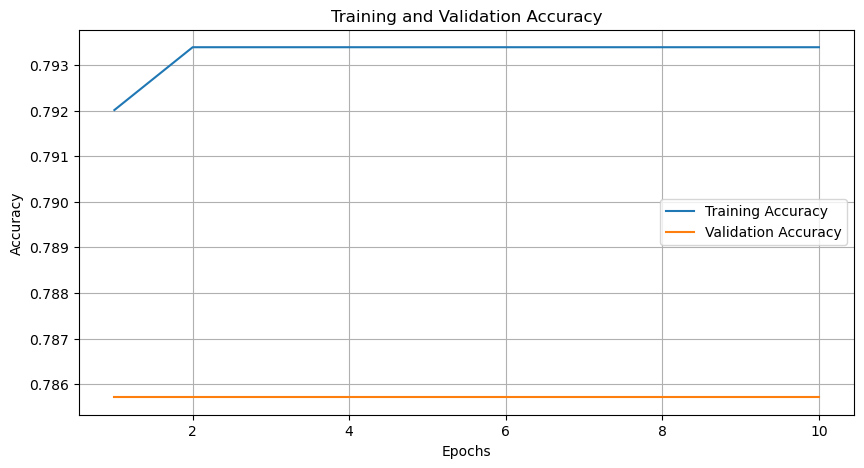

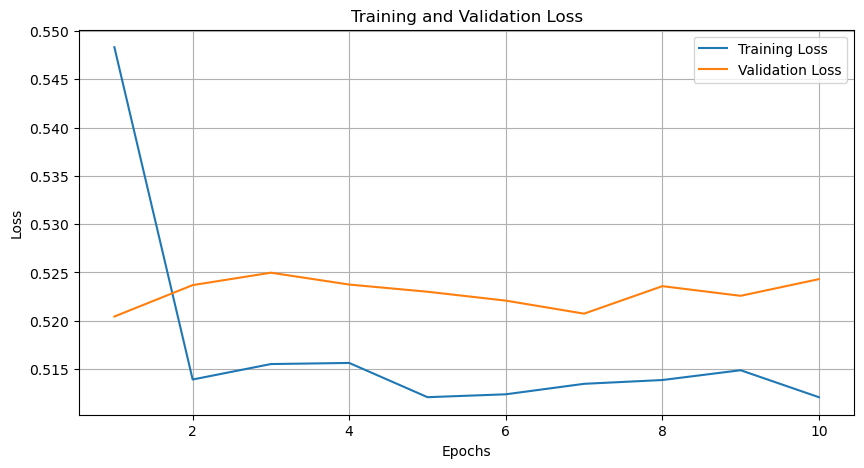

In [15]:
# Performance history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# Training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# The model on the test dataset
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.7939 - loss: 0.5085
Test Loss: 0.5085
Test Accuracy: 0.7939
Test Accuracy (%): 79.39 %


In [17]:
# Prediction probabilities
y_pred_probability = model.predict(X_test_padded)

# Probabilities into binary predictions
y_pred = (y_pred_probability >= 0.5).astype(int).ravel()

# Accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

# Classification report
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Classical', 'AI'],
    zero_division=0
))

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step
Accuracy: 0.7939

Classification Report:

              precision    recall  f1-score   support

   Classical       0.79      1.00      0.89       181
          AI       0.00      0.00      0.00        47

    accuracy                           0.79       228
   macro avg       0.40      0.50      0.44       228
weighted avg       0.63      0.79      0.70       228



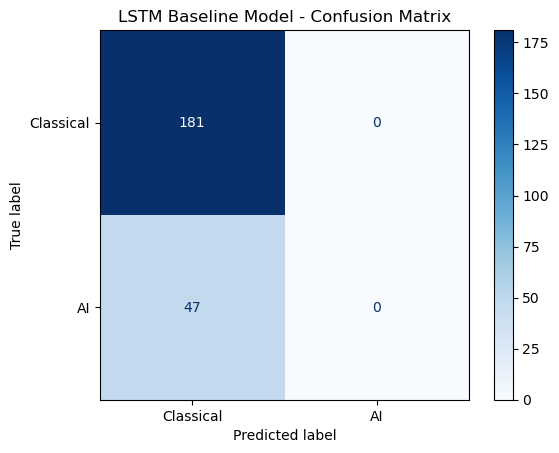

Confusion Matrix:
[[181   0]
 [ 47   0]]


In [22]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Classical', 'AI']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('LSTM Baseline Model - Confusion Matrix')
plt.show()

print("Confusion Matrix:")
print(cm)

In [19]:
# Final training and validation metrics
final_train_accuracy = history.history['accuracy'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]

final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

# Performance summary
performance = pd.DataFrame({
    'Metric': [
        'Training Accuracy',
        'Validation Accuracy',
        'Test Accuracy',
        'Training Loss',
        'Validation Loss',
        'Test Loss'
    ],
    'Value': [
        final_train_accuracy,
        final_val_accuracy,
        test_accuracy,
        final_train_loss,
        final_val_loss,
        test_loss
    ]
})

display(performance)

,Metric,Value
0,Training Accuracy,0.793388
1,Validation Accuracy,0.785714
2,Test Accuracy,0.793860
3,Training Loss,0.512068
4,Validation Loss,0.524302
5,Test Loss,0.508479


**Model generalisation**

The baseline LSTM model achieved a training accuracy of 79.34%, validation accuracy of 78.57%, and test accuracy of 79.39%. Training and validation accuracy remained relatively stable across the ten epochs, indicating that the model's overall accuracy did not improve significantly during training.

Although the test accuracy was approximately 79%, the classification report and confusion matrix showed that the model failed to correctly identify any AI abstracts. All 47 AI abstracts in the test dataset were incorrectly classified as Classical.

This indicates that the model was strongly influenced by the class imbalance in the dataset, where Classical abstracts represented a much larger proportion of the records than AI abstracts. Therefore, accuracy alone does not provide a complete assessment of the model's predictive performance.

The baseline model demonstrates that further improvements are required, particularly to improve the identification of AI research abstracts.